In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.ticker import MultipleLocator

# MLB Contract Efficiency Analysis
*Is your team wasting money?*

Analysis is broken into seven sections:

1. League Wide Trends
2. Team-Year analysis - most efficient teams relative to results
3. Individual team time series efficiency analysis
4. Dead Money Analysis - Where is the waste?
5. Contract Efficiency+ (CE+) - A standardized spending efficiency metric
6. Pareto Frontier - A theory about the Rays dominance
7. Conclusions

**Each section contains multiple charts and tables**, each chart has an accompanying markdown cell **above**, analyzing the results.

Data Sourcing:

Payroll data is sourced from Spotrac.com and covers the period 2011 - 2025. All 2020 data was excluded throughout the analysis because of the shortening of the season. All WAR data was sourced from fangraphs.com and aggregated to the team-year level. fWAR was chosen as the value metric because bWAR uses RA/9 which I have deemed to be an ineffective measure of pitcher value. 

Adjustments:

All payroll values are inflation adjusted using CPI-U data sourced from FRED for 2011-2025. All amounts are represented in the units of 2025 US dollars.



In [5]:
#Build Master Dataframe analysis visuals will reference
efficiency = pd.read_csv('Efficiency_Final.csv')
teams = pd.read_csv('Teams.csv')

#Clean columns
efficiency.columns = efficiency.columns.str.strip()
teams.columns = teams.columns.str.strip()

name_fix = {
    'ANA': 'LAA',   
    'MON': 'WSN',   
    'FLA': 'MIA',   
    'TBD': 'TBR',   
    'OAK': 'ATH',   
}
teams['Team'] = teams['franchID'].replace(name_fix)

#Merge in W and L and clean
main_df = efficiency.merge(
    teams[['Team', 'yearID', 'W', 'L']],
    left_on=['Team', 'Year'],
    right_on=['Team', 'yearID'],
    how='left'
)

main_df['injured_payroll_real'] = (
    main_df['injured_payroll_real']
    .astype(str)
    .str.replace(',', '')
    .replace('-', np.nan)
)
main_df['injured_payroll_real'] = pd.to_numeric(main_df['injured_payroll_real'], errors='coerce')

payroll_and_war_cols = [
    'total_payroll_real', 'active_payroll_real', 'injured_payroll_real',
    'total_war', 'total_dollar_per_war', 'active_dollar_per_war', 'injured_dollar_per_war'
]

for col in payroll_and_war_cols:
    if col in main_df.columns:
        main_df[col] = (
            main_df[col]
            .astype(str)
            .str.replace(',', '')
            .str.strip()
            .replace('-', np.nan)
        )
        main_df[col] = pd.to_numeric(main_df[col], errors='coerce')



## 1. League Wide Trends

Total payroll is the inflation adjusted total payroll obligations of teams. Active payroll represents the inflation adjusted dollars spent on players on the 26-man roster. The difference is money spent that is not directly contributing on the field (injuries, retained salaries,  AAAA guys). 

All seasons pre 2015 were dropped due to missing injury data biasing active $/WAR estimates. Additionally, all team-years with missing injury data 2015-2025 were dropped individually (4 observations)

**Chart 1:**
Since league wide WAR is capped at 1000 per year, the chart also closely follows average payroll expenditure league wide per year. This explains the valley we see post 2019. 2020 data was excluded from the analysis because it only represents a 60 game sample but dollars per WAR bottoms out in 2021 before rising again likely because of team's cutting back on spending after the lost revenue in 2020. This is why we see dollars per WAR normalize again post 2023 when teams had financially recovered.


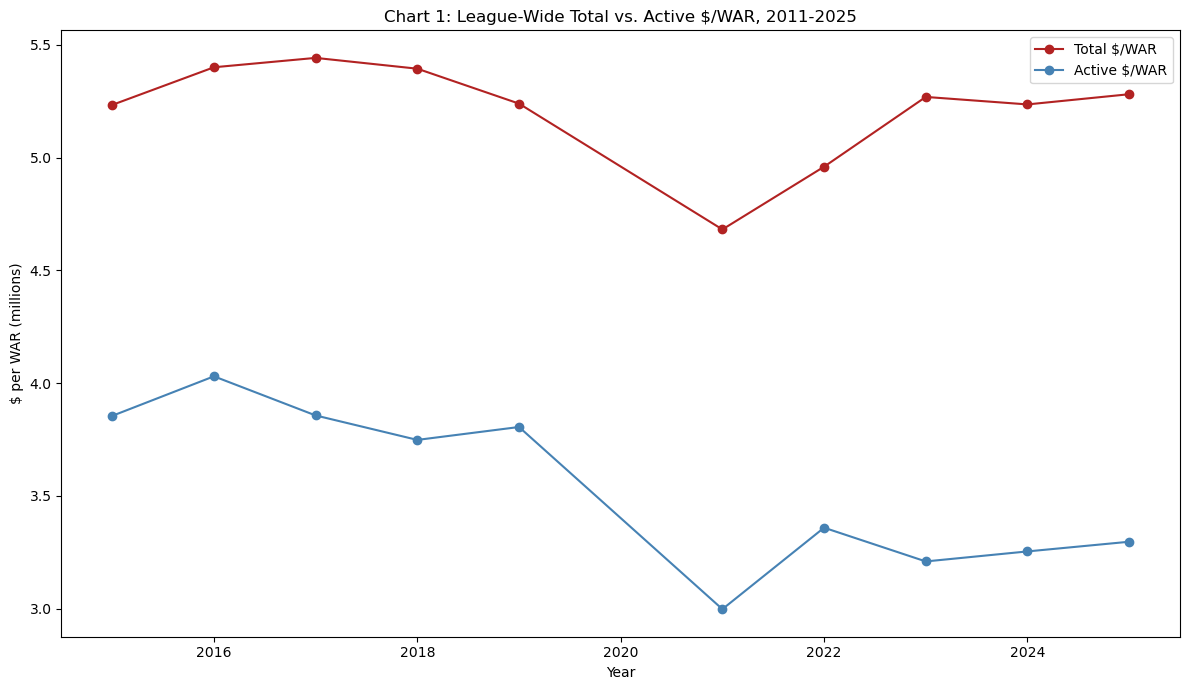

In [ ]:
#Chart 1: Total $/WAR vs Active $/WAR Chart
vis_one = main_df[main_df['Year'] >= 2015].copy()
vis_one = vis_one.dropna(subset=['injured_payroll_real'])

league_yearly = vis_one.groupby('Year').agg(
    total_payroll=('total_payroll_real', 'sum'),
    active_payroll=('active_payroll_real', 'sum'),
    total_war=('total_war', 'sum')
)
#Scale to Millions
league_yearly['total_dollar_per_war'] = (league_yearly['total_payroll']/1000000) / league_yearly['total_war']
league_yearly['active_dollar_per_war'] = (league_yearly['active_payroll']/1000000) / league_yearly['total_war']

#Plot
plt.figure(figsize=(12, 7))
plt.plot(league_yearly.index, league_yearly['total_dollar_per_war'], marker='o', label='Total $/WAR', color='firebrick')
plt.plot(league_yearly.index, league_yearly['active_dollar_per_war'], marker='o', label='Active $/WAR', color='steelblue')
plt.xlabel('Year')
plt.ylabel('$ per WAR (millions)')
plt.title('Chart 1: League-Wide Total vs. Active $/WAR, 2011-2025')
plt.legend()
plt.tight_layout()
plt.show()

**Table 1:**

The gap between total and active dollars per WAR widens on average from 1.484 million per WAR pre 2020, to 1.86 million per WAR post 2020. This means over the last 5 years teams have been spending significantly less on players actively contributing value on the field. While $/WAR remains constant, teams are spending more money inefficiently on players not contributing to the team's total WAR. The widening gap indicates that injury payrolls have likely been rising over last 5 years. 

In [ ]:
#Table 1: Gap Between Active and Total dollars per WAR and gap percentage of total
league_yearly = vis_one.groupby('Year').agg(
    total_payroll=('total_payroll_real', 'sum'),
    active_payroll=('active_payroll_real', 'sum'),
    total_war=('total_war', 'sum')
)
#League Dollars per WAR
league_yearly['total_dollar_per_war'] = league_yearly['total_payroll'] / league_yearly['total_war']
league_yearly['active_dollar_per_war'] = league_yearly['active_payroll'] / league_yearly['total_war']

#The gap between total and active dollars per WAR, in millions
league_yearly['gap_millions'] = (league_yearly['total_dollar_per_war'] - league_yearly['active_dollar_per_war']) / 1_000_000

league_yearly['gap_pct'] = (league_yearly['gap_millions'] * 1_000_000) / league_yearly['total_dollar_per_war'] * 100
print('Table 1:')
print(league_yearly[['total_dollar_per_war', 'active_dollar_per_war', 'gap_millions', 'gap_pct']].round(2))

Table 1:
      total_dollar_per_war  active_dollar_per_war  gap_millions  gap_pct
Year                                                                    
2015            5233468.97             3854491.98          1.38    26.35
2016            5400297.45             4029746.74          1.37    25.38
2017            5441841.03             3856274.50          1.59    29.14
2018            5393953.50             3747784.60          1.65    30.52
2019            5239104.37             3805018.84          1.43    27.37
2021            4681135.49             2997244.86          1.68    35.97
2022            4959293.97             3358457.55          1.60    32.28
2023            5268739.96             3208870.32          2.06    39.10
2024            5235525.85             3253283.32          1.98    37.86
2025            5280735.02             3296219.17          1.98    37.58


**Chart 2:**

This chart validates the idea that teams have been spending more money on injured players. Over the last 5 years we see Injury spending take a sharp rise. This could be also in part due to higher instances of injuries post 2020 because of the COVID IL and the decreased workload of the 2020 season leaving some players underconditioned.  

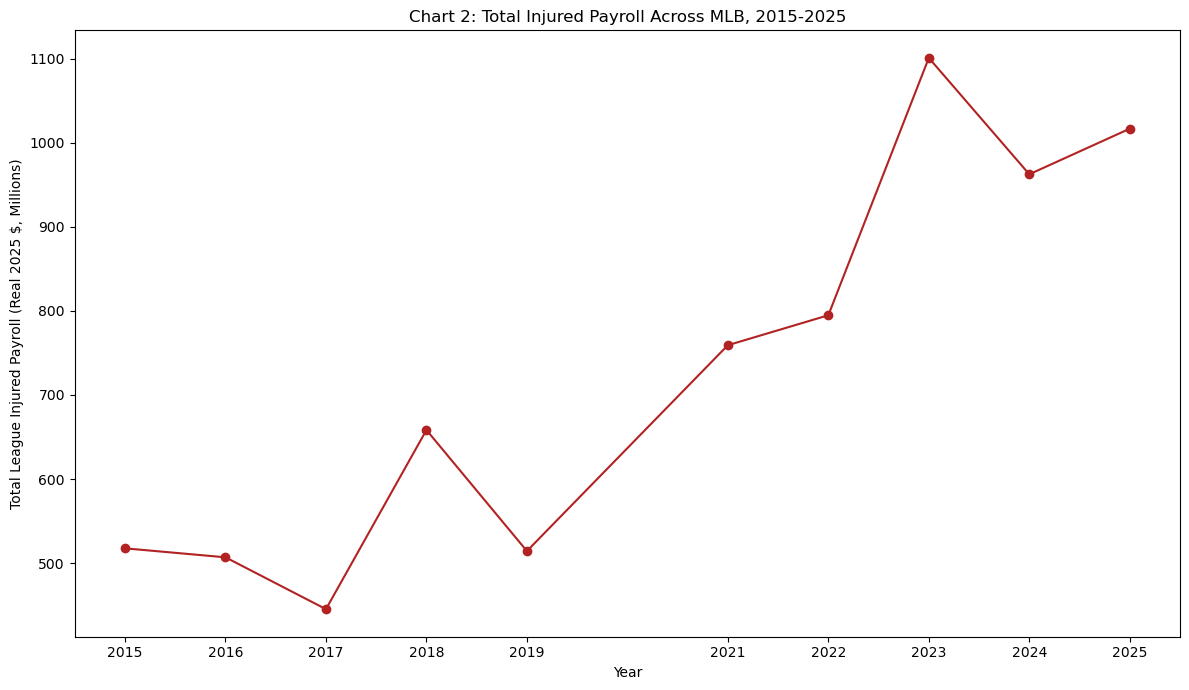

In [8]:
#Chart 2: Injury Payroll League-Wide Over Time
injured_yearly = vis_one.groupby('Year')['injured_payroll_real'].sum()

#Plot
plt.figure(figsize=(12, 7))
plt.plot(injured_yearly.index, injured_yearly.values / 1_000_000, marker='o', color='firebrick')
plt.xlabel('Year')
plt.ylabel('Total League Injured Payroll (Real 2025 $, Millions)')
plt.title('Chart 2: Total Injured Payroll Across MLB, 2015-2025')
plt.xticks(injured_yearly.index)
plt.tight_layout()
plt.show()

**Chart 3:**

This chart shows each team's average total payroll across the 2011-2025 period. It provides context for small and large market teams. Team position on this chart will be referenced in analysis throughout the notebook. The whiskers represent one standard deviation of each team's payroll in either direction. 

The New York Yankees and Los Angeles Dodgers dominate the average payroll rankings. However, New York shows a much tighter spread with more consistent spending year in and out while LA has lower payroll years in 2011 & 2012 that likely inflates their sd. The Giants & Angels are also notable at 6 and 7 on this list. While the Giants have two world series championships within the scope of the data, their spending remains high and results have severely declined in the last decade. Similarly, the Angels with a consistent and large payroll have found very little success making the playoffs only once in this wide window.

On the opposite end of the graph, the Tampa Bay Rays have the lowest average payroll in baseball over this period **and** the tightest payroll spread. Other notable successful small market teams like MIL & CLE sit at #25 and #26 largest in payroll respectively, near the bottom. The dynasty Houston Astros come in roughly average on the graph as well despite having immense playoff success in this window.

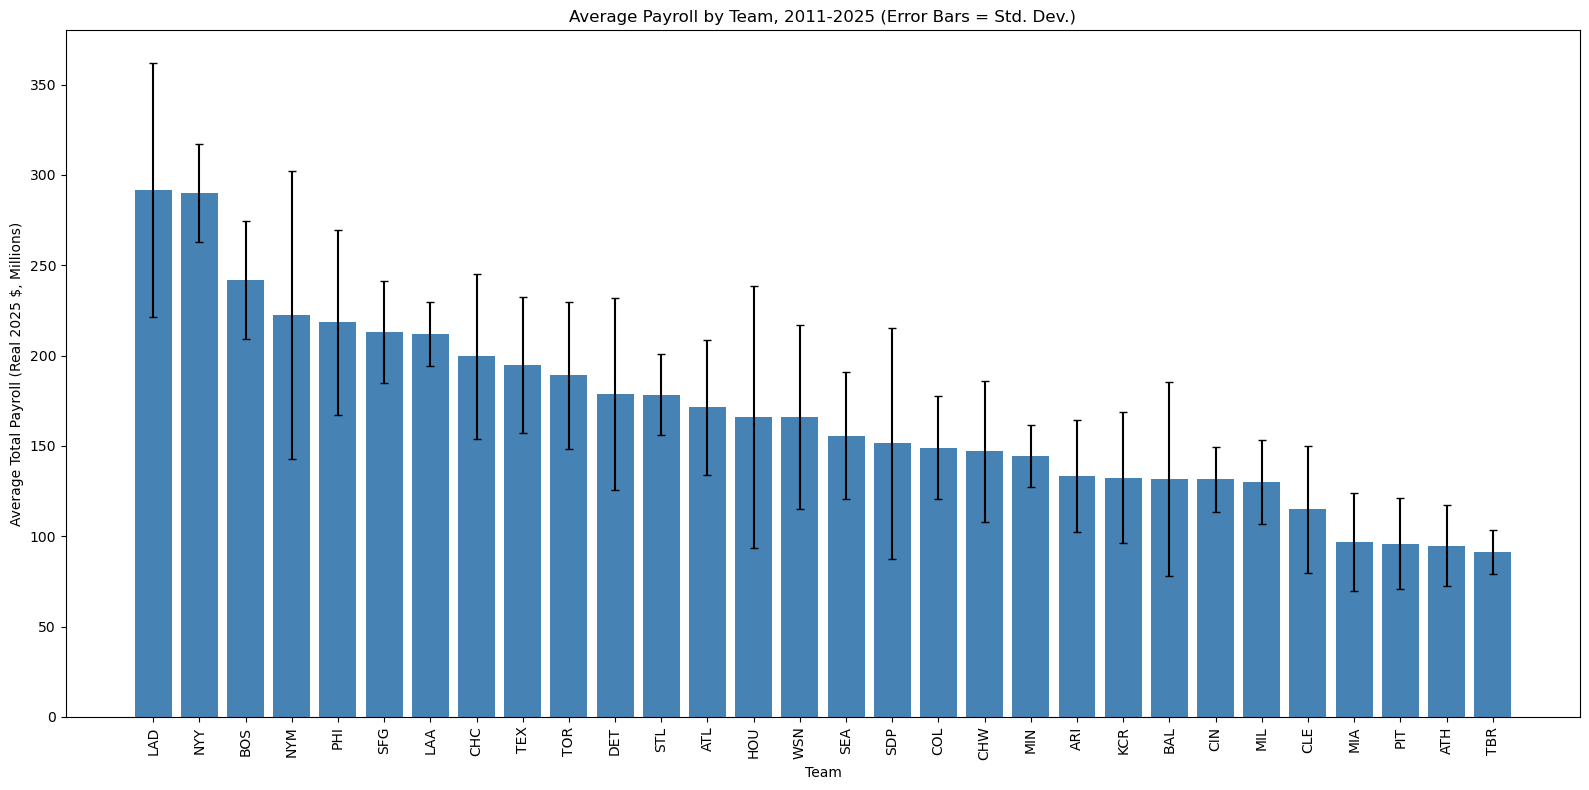

In [10]:
#Chart 3: Average Payroll per team with spread
payroll_stats = main_df.groupby('Team')['total_payroll_real'].agg(['mean', 'std']) / 1_000_000
payroll_stats = payroll_stats.sort_values('mean', ascending=False)

plt.figure(figsize=(16, 8))
plt.bar(payroll_stats.index, payroll_stats['mean'], yerr=payroll_stats['std'], color='steelblue', capsize=3)
plt.xlabel('Team')
plt.ylabel('Average Total Payroll (Real 2025 $, Millions)')
plt.title('Average Payroll by Team, 2011-2025 (Error Bars = Std. Dev.)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 2. Team-Year Payroll vs WAR efficiency analysis

Total payroll vs total WAR plotted on a centered axis for every team-year in the dataset (420 observations). Shows the teams with highest and lowest spending combined with most and least productive rosters assembled. 

**Chart 1:**

**Green**:
Unsurprisingly to most baseball fans, the Tampa Bay Rays hold a near monopoly over the best quadrant in the graph. The **cheap** teams with **extremely productive** rosters. The Tampa organization is consistently the most efficient org, getting the most value for the least money. The Rays are widely considered one of the most analytically advanced front offices and masters of the trade acquisition, this is allows them to amass talented rosters of young players on rookie contracts who eventually earn lucrative contracts with other teams in free agency. 

**Blue**:
Similarly to the Rays, the Los Angeles Dodgers have a monopoly over the top right quadrant of the graph, their teams are **expensive** but **elite**. The Dodgers have assembled a dynasty by being one of the best analytics and development organizations with one of the biggest budgets of all teams. The Dodgers spend with extreme efficiency relative to the size of the market. They also tout one of the top farm systems in baseball making them a contender for best organization in baseball.

**Red**:
In the bottom right now we can see the teams that spent the **most** money and got the **least** value. Spearheading this group is the 2023 New York Mets with a historically large payroll rivalled only by the Dodgers. However, the 2023 Mets were uncompetitive, missing the playoffs and finishing fourth in the division despite having the **highest** payroll in baseball that year. 

The Rockies and Giants also both appear in this high spending low production quadrant. Both of these teams very often spend more than league average, however they are **significantly worse** than other teams at converting this increased spending into value. These organizations roll out 100+ million dollar rosters that regularly struggle to win half of their games.

**Yellow**:
This section is the least insightful, showing front offices who did not spend on their teams which then performed poorly. Organizations that are routinely in this quadrant are uncompetitive low payroll rosters like the Athletics. However, all the franchises labelled in this quadrant have assembled productive rosters within the range of this data and therefore this quadrant is mostly teams rebuilding rosters.

C:\Users\joshs\AppData\Local\Temp\ipykernel_8108\1341798493.py:38: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_per_quadrant = vis_two.groupby('quadrant').apply(lambda g: g.nlargest(5, 'dist')).reset_index(drop=True)


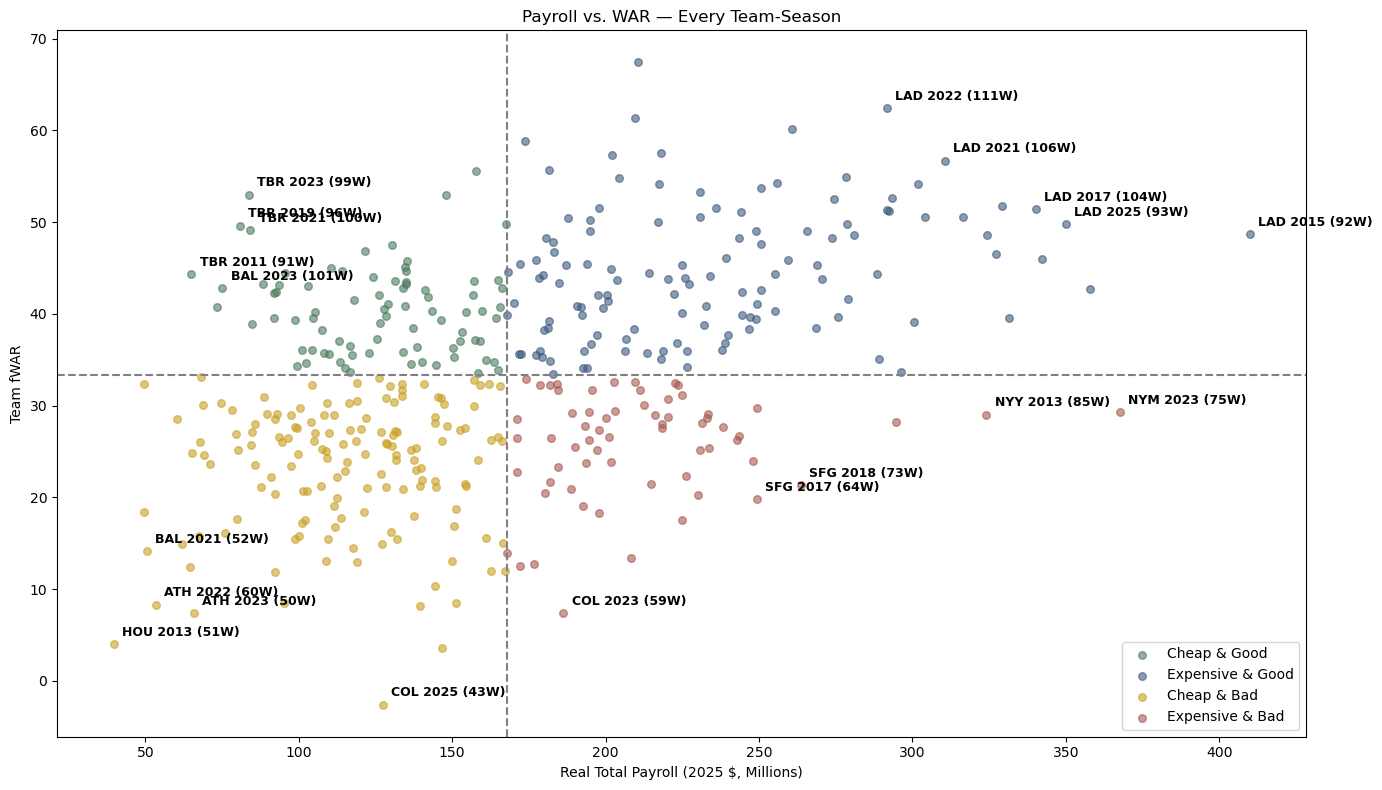

In [11]:
# Chart 1: 4-Quadrant payroll vs WAR graph -- Who's the most efficient relative to spending?
vis_two = main_df.copy()
vis_two['payroll_millions'] = vis_two['total_payroll_real'] / 1_000_000

# x and y axes
avg_payroll = vis_two['payroll_millions'].mean()
avg_war = vis_two['total_war'].mean()

# classify teams into quadrants
def quadrant(row):
    cheap = row['payroll_millions'] < avg_payroll
    good = row['total_war'] >= avg_war
    if cheap and good: return 'Cheap & Good'
    if not cheap and good: return 'Expensive & Good'
    if cheap and not good: return 'Cheap & Bad'
    return 'Expensive & Bad'

vis_two['quadrant'] = vis_two.apply(quadrant, axis=1)

colors = {'Cheap & Good': '#4C7A5C', 'Expensive & Good': '#3D5A80',
          'Cheap & Bad': '#C9A227', 'Expensive & Bad': '#A65A4E'}

# plot
plt.figure(figsize=(14, 8))
for q, color in colors.items():
    subset = vis_two[vis_two['quadrant'] == q]
    plt.scatter(subset['payroll_millions'], subset['total_war'], color=color, alpha=0.6, s=30, label=q)

plt.axvline(avg_payroll, color='gray', linestyle='--')
plt.axhline(avg_war, color='gray', linestyle='--')

# label quadrant outliers
vis_two['dist'] = (
    (vis_two['payroll_millions'] - avg_payroll).abs() / vis_two['payroll_millions'].std() +
    (vis_two['total_war'] - avg_war).abs() / vis_two['total_war'].std()
)

top_per_quadrant = vis_two.groupby('quadrant').apply(lambda g: g.nlargest(5, 'dist')).reset_index(drop=True)

for _, row in top_per_quadrant.iterrows():
    plt.annotate(f"{row['Team']} {row['Year']} ({row['W']}W)",
                 (row['payroll_millions'], row['total_war']), xytext=(6, 6),
                 textcoords="offset points", fontsize=9, fontweight='bold')

# chart labels
plt.xlabel('Real Total Payroll (2025 $, Millions)')
plt.ylabel('Team fWAR')
plt.title('Payroll vs. WAR — Every Team-Season')
plt.legend(loc='lower right')
plt.gca().ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

In [12]:
#Team quadrant count
quadrant_counts = pd.crosstab(vis_two['Team'], vis_two['quadrant'])

# Reorder columns to match the color legend order
quadrant_counts = quadrant_counts[['Cheap & Good', 'Expensive & Good', 'Cheap & Bad', 'Expensive & Bad']]

cheap_good = quadrant_counts[['Cheap & Good']].sort_values('Cheap & Good', ascending=False)
expensive_good = quadrant_counts[['Expensive & Good']].sort_values('Expensive & Good', ascending=False)
cheap_bad = quadrant_counts[['Cheap & Bad']].sort_values('Cheap & Bad', ascending=False)
expensive_bad = quadrant_counts[['Expensive & Bad']].sort_values('Expensive & Bad', ascending=False)


**Table 1:**

These quadrant counts show the cheap teams who are also the most consistent winners. Some lower payrolls teams like PIT & MIA consistently look good in Dollars/WAR but we see they aren't consistently achieving strong roster performances, rather just rostering cheap and mediocre players. The best small market teams: TBR, MIL, CLE, ATH, all achieve similarly efficient Dollars/WAR numbers but do it with a much higher and more consistent overall roster fWAR and more consistent winning seasons. 

Tampa Bay's success is even more impressive when you contextualize that they play in the AL East, one of the consensus toughest divisions in baseball. Their small market rivals, CLE & MIL both play in two of the consensus weakest divisions in baseball. Tampa Bay achieves superior levels of success and efficiency while in a much tougher league environment than other prominent small market clubs.   

In [13]:
#Table 1: Green quadrant
cheap_good.head(10)

quadrant,Cheap & Good
Team,
TBR,11
MIL,9
CLE,7
ATH,6
BAL,5
ARI,4
SEA,4
PIT,4
CIN,4


**Table 2:**

We can see from these counts that the Los Angeles Angels are by far the **worst** team in terms of efficiency. They routinely spend lots of money for very little on field value. The nine-figure contracts of Mike Trout, Anthony Rendon, and Albert Pujols are likely driving this number. Each of these contracts either ran into consistent injuries or sharp declines in production that severely impacted WAR production. 

We also see TEX & SFG at 7 & 6 red quadrant appearances respectively. These two teams consistently run ~200 million dollar payrolls that produce below league average WAR values. This is particularly interesting because these teams don't carry the same reputation as poor spenders that the Angels do.  

In [14]:
#Table 2: Red Quadrant
expensive_bad.head(10)

quadrant,Expensive & Bad
Team,
LAA,11
TEX,7
SFG,6
BOS,5
TOR,4
PHI,4
NYM,3
CHW,3
COL,3


**Table 3:**

The two teams that dominate the Blue quadrant are the Yankees and Dodgers who also dominate the average payroll rankings league wide. They are able to consistently spend money and translate that money into valuable rosters that produce wins.

We see SFG, PHI, BOS, NYM and TOR show up prominently on this list but also in the Red quadrant list, suggesting that these teams consistently spend money, but their roster performance and win totals are somewhat volatile. This would result in a higher number of expensive teams that are BOTH good and bad. 

For interesting results we can also look at teams that DONT overlap lists: HOU, CHC, STL. This suggests that these teams either manage to be consistently good *or* when they're bad, it's during a deliberate lower payroll rebuilding period.  

In [15]:
#Table 3: Blue Quadrant 
expensive_good.head(10)

quadrant,Expensive & Good
Team,
NYY,12
LAD,12
BOS,9
STL,8
HOU,8
SFG,8
CHC,8
NYM,7
TOR,7


**Table 4:**

This table shows teams that post good $/WAR ratios without translating that into competitive rosters. A low payroll paired with modest output can still look "efficient" on a dollars-per-win basis.

This table lets us separate those two cases. MIA, PIT, MIN, and CIN show up here as teams that can look efficient in dollars/WAR terms but aren't consistently rostering competitive teams alongside it. This helps distinguish small-market teams with genuinely strong front offices from those that are simply small and non-competitive.

In [16]:
#Table 4: Yellow Quadrant
cheap_bad.head(10)

quadrant,Cheap & Bad
Team,
MIA,13
PIT,10
MIN,10
CIN,10
COL,9
SDP,9
ATH,8
CHW,8
KCR,8


## 3. Time Series Team Spending Efficiency Analysis

Team dollars/WAR trend line is plotted in black vs the league average dollars/WAR in grey. Stretches where team were spending efficiently are represented with green shading, inefficient stretches are shaded red. The ideal team would be both generally successful in terms of wins **and** exhibit a consistent linear trend near the bottom of this graph. 

**The Good:**

Looking at only the greenest team graphs we see: ATH, CLE, HOU, MIL, MIN, PIT, and TBR all stand out. We established that ATH, CLE, MIL, TBR are all had many talented rosters over this time period and are seemingly organizations with an above average ability to draft, develop, and pay talent. 

HOU & STL are two teams that stand out in the graph as larger market, higher average payroll teams, that also show remarkable spending efficiency despite their average payroll size. The graph shows most of the high payroll teams tend to have more *red* graphs sacrificing some efficiency to capture star free agents. 

**The Bad:**

Looking only at the reddest graphs in the chart we see: LAA, COL, SFG, NYY, TEX, DET, and BOS. The commonality between these teams is that they're all average to above average payroll teams. This makes sense, the more money you spend, the worse it's possible to be in terms of efficiency. The Angels lead the pack with a high payroll, very little success, and worsening dollars/WAR efficiency numbers. TEX, COL, and SFG were noted earlier as teams with high payrolls that haven't found significant success in recent years due in part to inefficient spending. While I believe that NYY and BOS are inefficient simply because they have a large enough budget they don't have to worry about spending efficiently.

**The Ugly:**

The only thing worse than a high payroll team wasting money is a lower payroll team wasting money. Every dollar needs to be doing its job. We see: BAL, KCR, and SEA are all teams in the bottom half of league wide average payroll but they don't show the same level of spending discipline and efficiency that the successful small market teams (TBR, MIL, etc) do. If your budget is smaller than most teams then every dollar has to be doing more to be competitive, these teams haven't been able to consistently produce that. 

**The Interesting:**

LAD, STL, and ATL are all teams with average payrolls in the top half of the league. While, higher payroll teams tend to be less efficient per dollar these teams defy that trend to varying degrees. The LAD average 96 wins per year over this period, as well as the highest payroll in the league. Despite this, they manage to remain much closer to league average in terms of efficiency than the second place NYY who average 91 wins. This efficiency differential at such a large payroll size likely drives much of the win gap between the two franchises. STL & ATL are 3rd and 6th in average wins over this period as high payroll teams that have also shown a remarkable ability to maintain a roughly consistent average payroll efficiency even as they scale total payroll. 



C:\Users\joshs\AppData\Local\Temp\ipykernel_8108\2242371517.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  league_avg = vis_three.groupby('Year').apply(


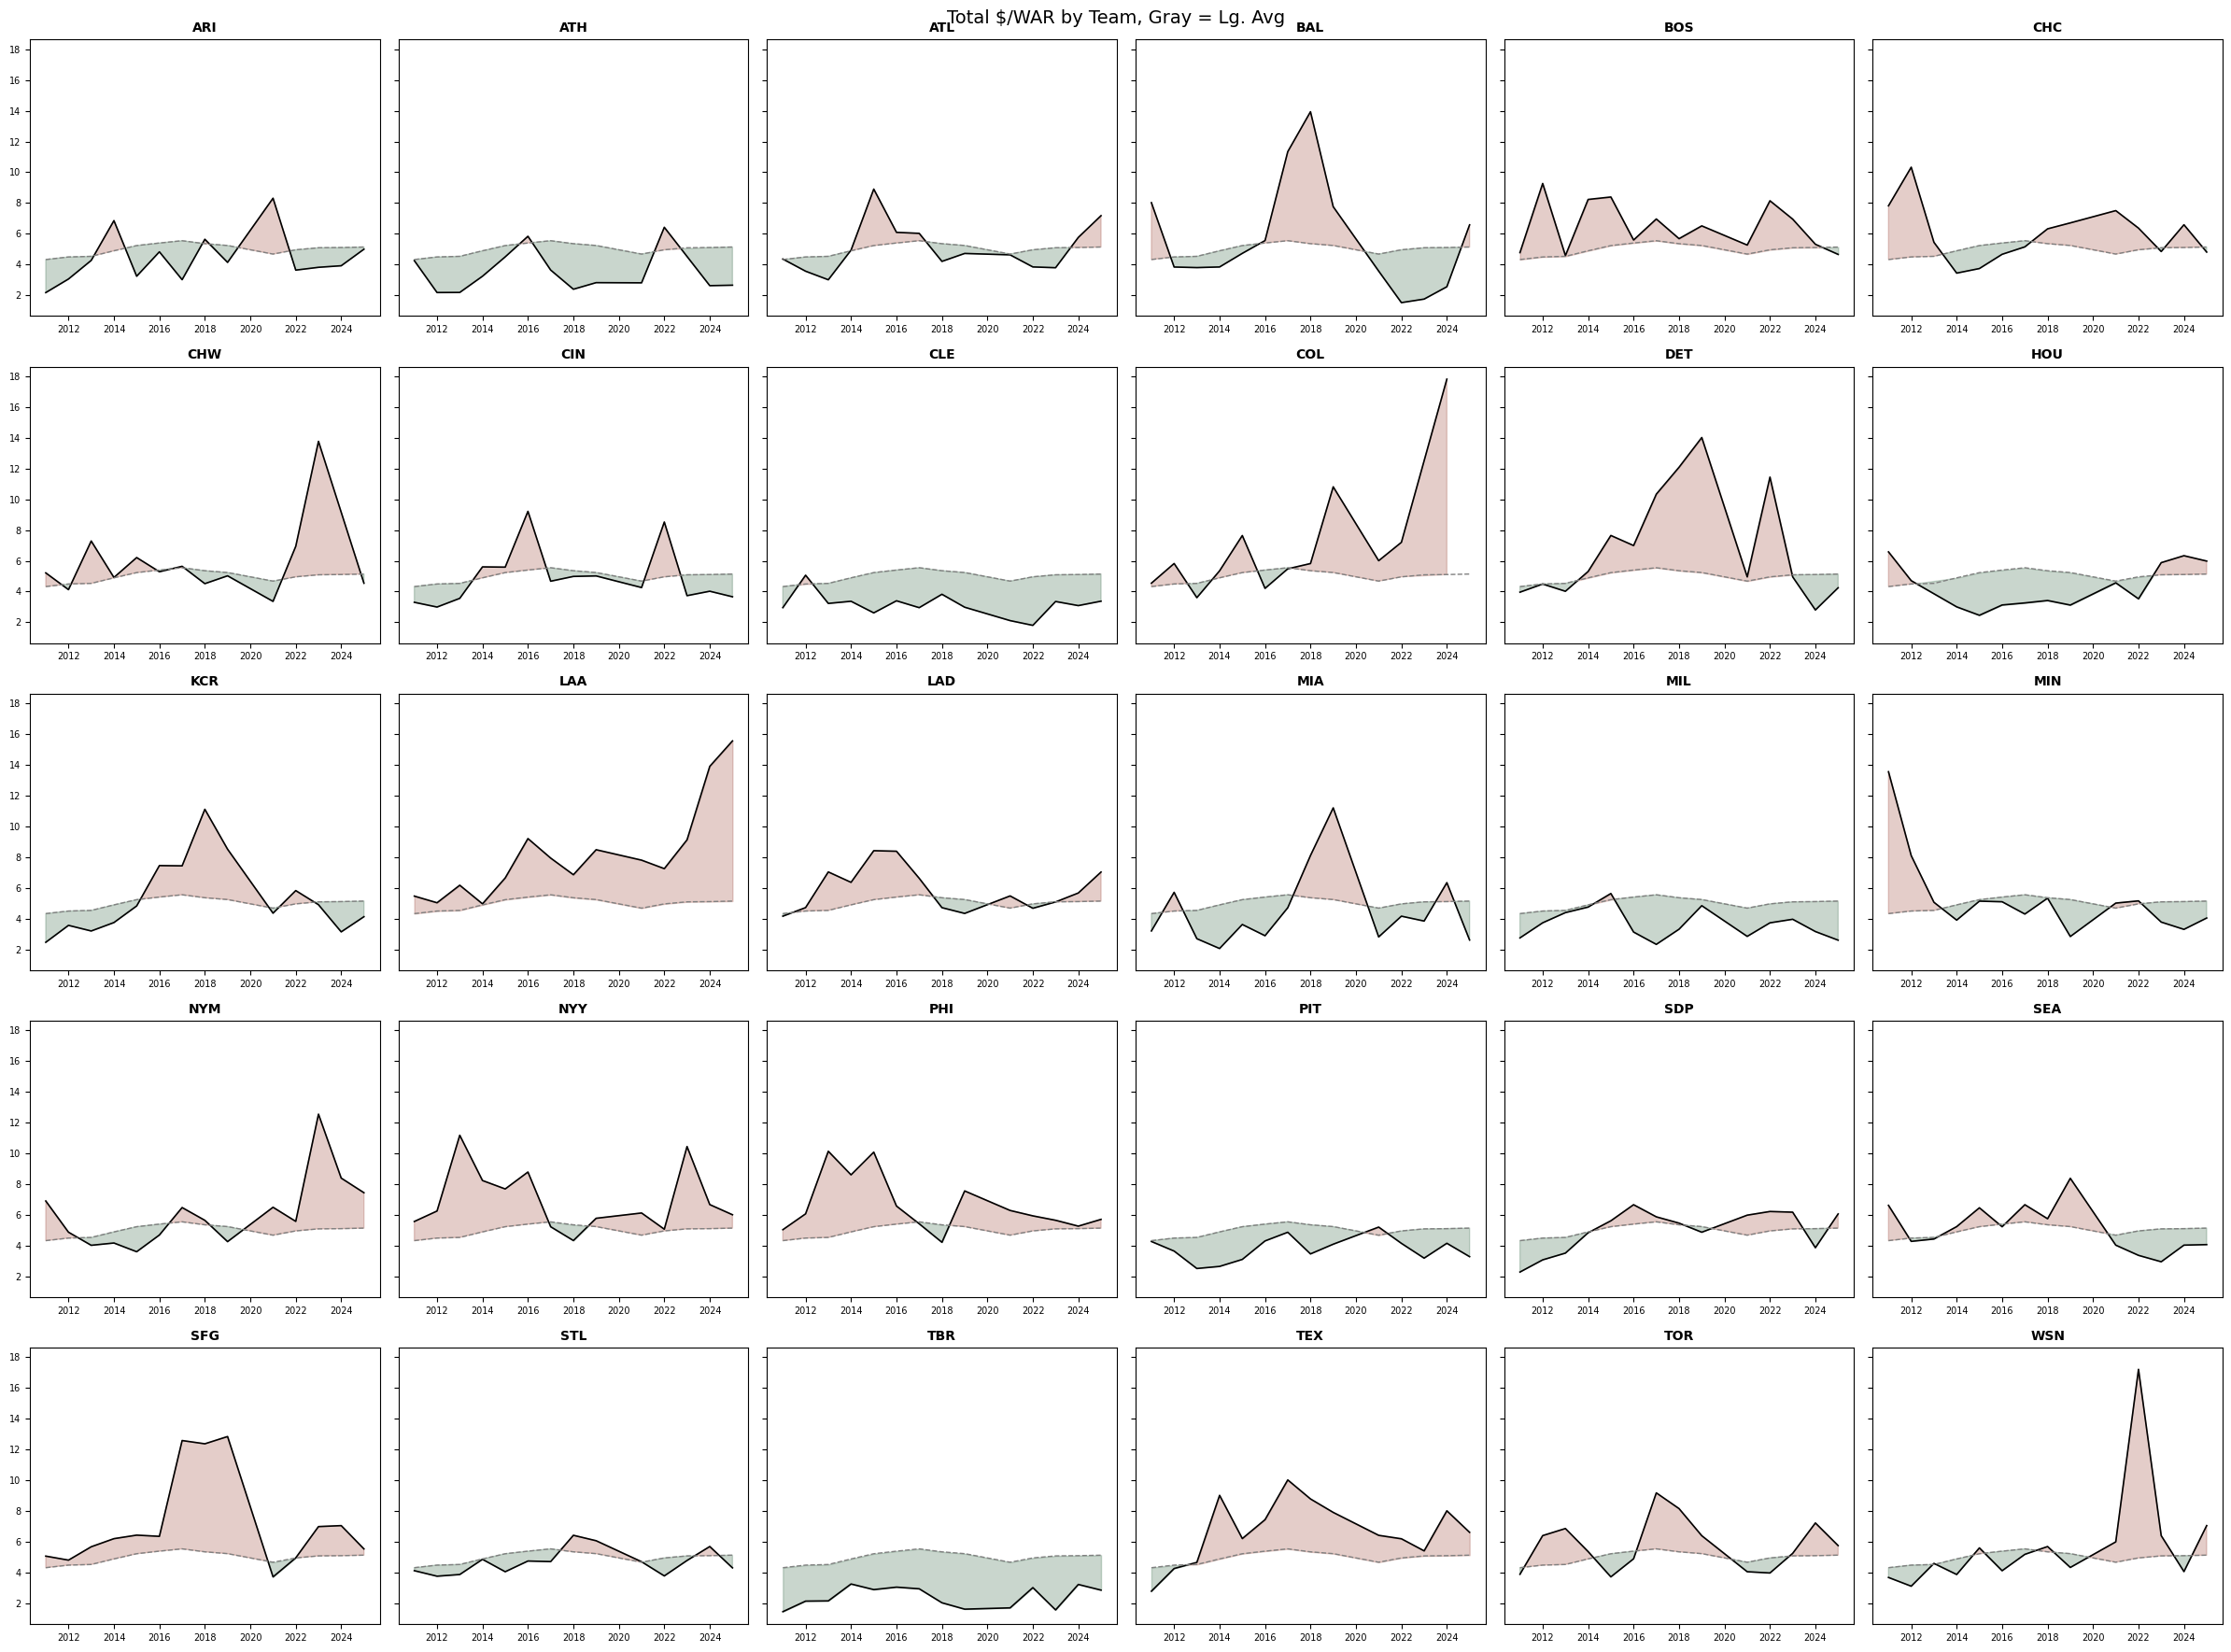

In [18]:
#Team $/WAR year over year
vis_three = main_df.copy()
vis_three = vis_three[vis_three['total_war'] >= 7.5]
vis_three['dollar_per_war_millions'] = vis_three['total_dollar_per_war'] / 1_000_000

teams = sorted(vis_three['Team'].unique())

#League average benchmark line
league_avg = vis_three.groupby('Year').apply(
    lambda g: g['total_payroll_real'].sum() / g['total_war'].sum() / 1_000_000
)

#Build grid
fig, axes = plt.subplots(5, 6, figsize=(24, 18), sharey=True)
axes = axes.flatten()

#Plot each team
for i, team in enumerate(teams):
    ax = axes[i]
    team_data = vis_three[vis_three['Team'] == team].sort_values('Year')

    ax.plot(team_data['Year'], team_data['dollar_per_war_millions'], color='black', linewidth=1.2)
    ax.plot(league_avg.index, league_avg.values, color='gray', linewidth=1, linestyle='--')

#Shade the difference between team and league average
    merged = team_data.merge(league_avg.rename('league_avg'), left_on='Year', right_index=True)
    ax.fill_between(merged['Year'], merged['dollar_per_war_millions'], merged['league_avg'],
                     where=(merged['dollar_per_war_millions'] >= merged['league_avg']),
                     color='#A65A4E', alpha=0.3, interpolate=True)
    ax.fill_between(merged['Year'], merged['dollar_per_war_millions'], merged['league_avg'],
                     where=(merged['dollar_per_war_millions'] < merged['league_avg']),
                     color='#4C7A5C', alpha=0.3, interpolate=True)

    ax.set_title(team, fontsize=10, fontweight='bold')
    ax.tick_params(labelsize=7)

#plot
fig.suptitle('Total $/WAR by Team, Gray = Lg. Avg', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
#Average wins per year
print(main_df.groupby('Team')['W'].mean().sort_values(ascending=False))

Team
LAD    96.214286
NYY    91.928571
STL    87.714286
CLE    86.714286
MIL    86.428571
ATL    86.428571
TBR    86.142857
BOS    85.785714
HOU    84.214286
SFG    82.642857
TOR    82.071429
CHC    81.785714
SEA    81.428571
PHI    81.428571
NYM    81.357143
WSN    81.285714
TEX    80.714286
ARI    79.071429
LAA    78.571429
ATH    78.500000
DET    78.214286
BAL    77.928571
SDP    77.285714
PIT    77.214286
CIN    76.500000
MIN    75.785714
KCR    75.285714
CHW    70.785714
MIA    70.571429
COL    69.571429
Name: W, dtype: float64


## 4. Dead/Wasted Money Analysis

Dead Money is calculated as (total payroll - 26 man payroll) and represents dollars spent that aren't contributing on field.

It was found that 26-man payroll values were systematically skewed in years without team injury payroll data, so all team-years without injury data were dropped from the dataset (109 obs).

At the bottom of the chart we have the Astros and the Yankees, this means that on average they spend the least of their total budgets on players not actively contributing on the 26-man roster. The Yankees appearance is likely influenced by having one of the largest payrolls in the league, meaning their denominator (total payroll) is quite large and their averages are not easily skewed by one big contract going down with injury.

 HOU, MIL, and STL appearances are much more interesting. These teams have moderate to low average payrolls, making them more sensitive to isolated unfortunate events, yet are able to consistently produce below average dead money values. These teams were also flagged in the efficiency analysis teams with moderate to higher spending that are able to sustain efficiency at higher payroll values. Together, this suggests that these are premier organizations with a real advantage in front office decision making. 

 Most interestingly we see the Rays, who we've flagged as THE most efficient team at converting dollars into wins, showing up near the top of this graph. Again, this could be influenced by the denominator effect as they have the lowest average payroll. However, we CAN conclude that the Rays don't achieve their success by having the highest percentage of their budget on the field, an interesting finding nonetheless. 

 The LAA also show up at the top of this chart, indicating that much of their inefficiency comes from having expensive players injured or off-field (Trout, Rendon, Pujols)
  



C:\Users\joshs\AppData\Local\Temp\ipykernel_8108\2867876592.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_by_team, labels=teams_sorted, vert=True, showfliers=False)


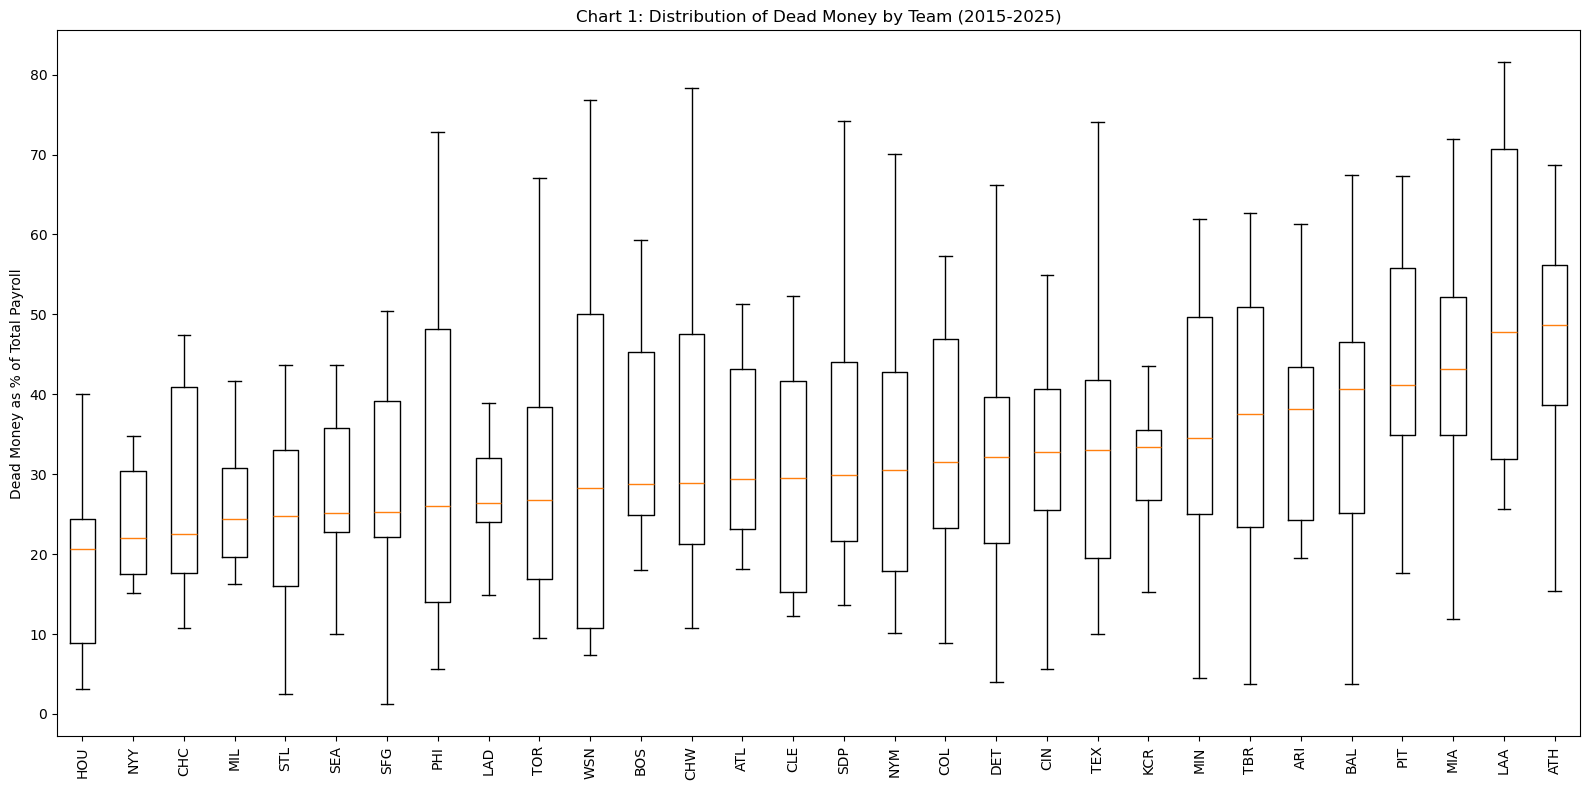

In [21]:
#Chart 1: Dead Money analysis
vis_four = main_df.copy()
vis_four = vis_four.dropna(subset=['injured_payroll_real'])

#Calculate dead money percentage
vis_four['dead_money_pct'] = (vis_four['total_payroll_real'] - vis_four['active_payroll_real']) / vis_four['total_payroll_real'] * 100

teams_sorted = vis_four.groupby('Team')['dead_money_pct'].median().sort_values().index

#Boxplots
plt.figure(figsize=(16, 8))
data_by_team = [vis_four[vis_four['Team'] == t]['dead_money_pct'] for t in teams_sorted]
plt.boxplot(data_by_team, labels=teams_sorted, vert=True, showfliers=False)

#Labels and title
plt.xticks(rotation=90)
plt.ylabel('Dead Money as % of Total Payroll')
plt.title('Chart 1: Distribution of Dead Money by Team (2015-2025)')
plt.tight_layout()
plt.show()


**OLS Regression:**

The output is a multiple regression with total payroll and dead money % as features regressed on Total Wins. Features were standardized due to different scaling.

**R^2 = 0.362**, meaning total payroll and dead money % can explain 36% of variance in team wins. Additionally, all model coefficients have a p-value of 0, showcasing a clear relationship

**Payroll:** +1 sd is associated with an additional almost 3.5 wins over the course of the year after controlling for dead money %. So total expenditure does have a relationship with overall success. 

**Dead Money %:** +1 sd (more dead money) is associated with declining almost 6 wins per year after controlling for total payroll. Remarkably, this relationship is stronger than that of payroll.

We cannot assert that increasing payroll or decreasing dead money **CAUSES** wins or losses. However, we can conclude they are strongly associated. We also cannot concretely determine the directionality, it's possible that teams with higher dead money tend to lose more, or teams that tend to lose more accrue more dead money from trades and such as a result of losing. We **can** say confidently that teams with lower dead money as a % of payroll do tend to win more games, after controlling for payroll. 

Note on standard errors: this regression pools team-year observations, but each team appears repeatedly (~14 times) rather than being a fully independent draw. This within-team correlation means the reported standard errors and p-values are likely somewhat optimistic.



In [22]:
# Standardize and run regression
X_std = vis_four[['total_payroll_real', 'dead_money_pct']].apply(lambda x: (x - x.mean()) / x.std())

model_dm_std = sm.OLS(vis_four['W'], sm.add_constant(X_std)).fit()
print(model_dm_std.summary())


                            OLS Regression Results                            
Dep. Variable:                      W   R-squared:                       0.362
Model:                            OLS   Adj. R-squared:                  0.358
Method:                 Least Squares   F-statistic:                     87.45
Date:                Sun, 02 Aug 2026   Prob (F-statistic):           8.37e-31
Time:                        18:20:15   Log-Likelihood:                -1164.2
No. Observations:                 311   AIC:                             2334.
Df Residuals:                     308   BIC:                             2346.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 80.9646      0

## 5. Contract Efficiency + (CE+)

Team-Years with total WAR below 7.5 were dropped because of exploding dollars/WAR values as WAR approaches 0 (5 obs dropped)

Contract Efficiency + is a simple standardization of dollars/WAR, reported on a "+" scale where 100 is average efficiency, a score of 115 represents a team 1 sd MORE efficient while 85 represents a team 1 sd LESS efficient.

TBR and LAA occupy the two tails by quite a large margin. The Angels were flagged earlier as the worst spenders in the league, largely due to high dead money rates and expensive player injuries and underperformance. The Rays have been extremely efficient and thus show up at nearly 120 CE+ on average over the period. 

**Green:** We see familar successful teams being CLE, MIL, and HOU prominently in this section the graph, further reinforcing their efficient narrative. 

**Red:** We can see the Dodgers again clearly show the most discipline of the large market teams in the league, representing the best of the red portion of the chart. COL, TEX, DET, and SFG also all appear as big spenders that are significantly below average (100) in terms of spending efficiency on average across this period. 




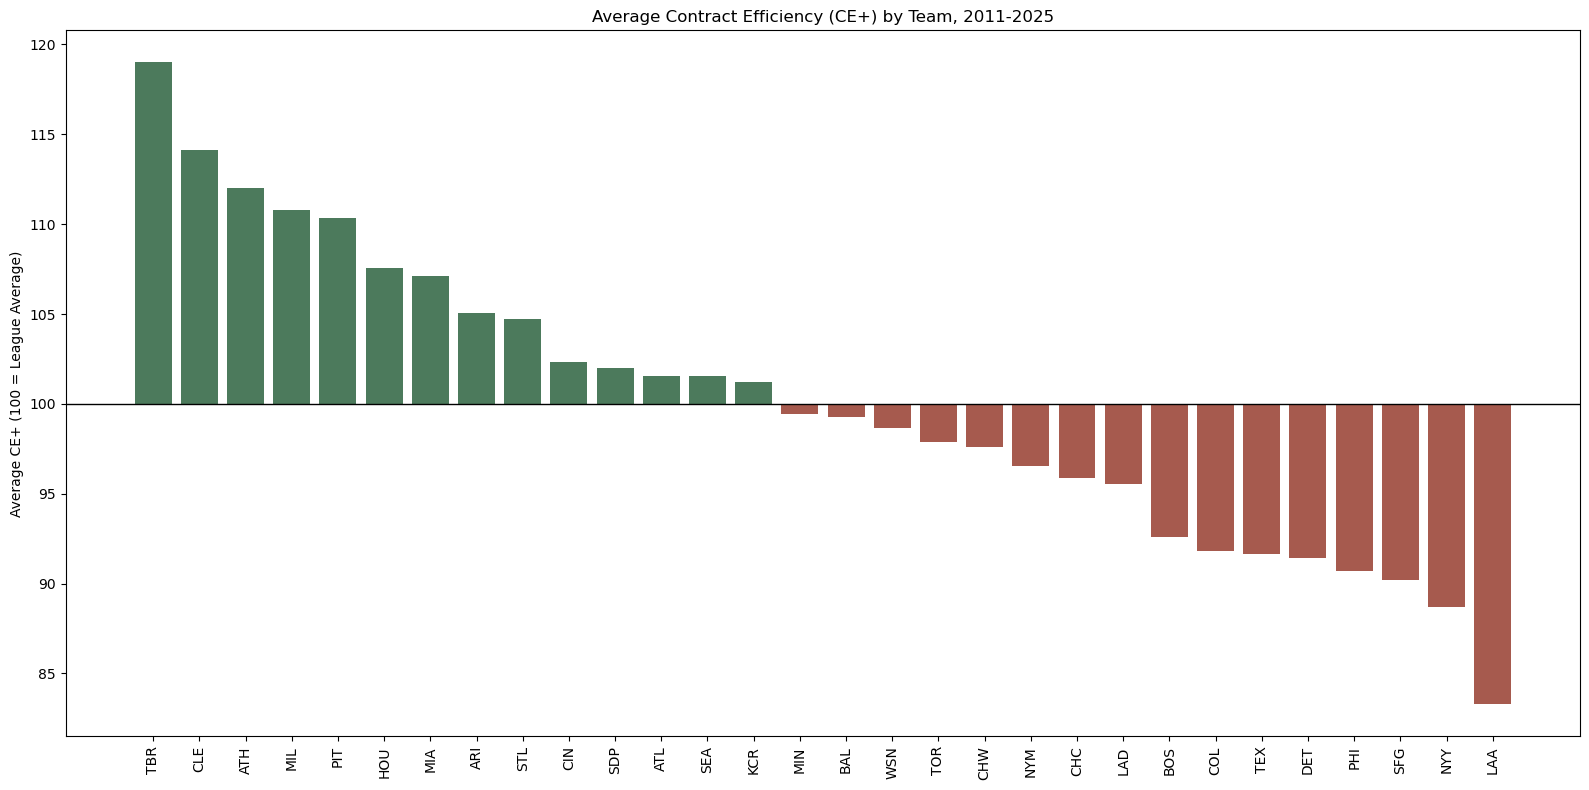

In [23]:
#CE+ standardized measure of contract efficiency
vis_five = main_df.copy()
vis_five = vis_five[vis_five['total_war'] >= 7.5]

#Standardize contract efficiency relative to league average
vis_five['avg_dollar_per_war'] = vis_five.groupby('Year')['total_dollar_per_war'].transform('mean')
vis_five['std_dollar_per_war'] = vis_five.groupby('Year')['total_dollar_per_war'].transform('std')

vis_five['z_dollar_per_war'] = (vis_five['total_dollar_per_war'] - vis_five['avg_dollar_per_war']) / vis_five['std_dollar_per_war']
vis_five['ce_plus'] = (100 - (15 * vis_five['z_dollar_per_war'])).round(0)

#graph it
team_ce = vis_five.groupby('Team')['ce_plus'].mean().sort_values(ascending=False)

colors = ['#4C7A5C' if v >= 100 else '#A65A4E' for v in team_ce.values]

plt.figure(figsize=(16, 8))
plt.bar(team_ce.index, team_ce.values - 100, bottom=100, color=colors)
plt.axhline(100, color='black', linewidth=1)
plt.ylabel('Average CE+ (100 = League Average)')
plt.title('Average Contract Efficiency (CE+) by Team, 2011-2025')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [24]:
#Top 10 CE+ Leaderboard
top_ten = vis_five[['Team', 'Year', 'W', 'L','ce_plus','total_payroll_real','total_war']].sort_values(['ce_plus'],ascending=False).head(10)

print(top_ten)

   Team  Year    W   L  ce_plus  total_payroll_real  total_war
5   TBR  2021  100  62    129.0            84165604       49.1
9   MIA  2014   77  85    125.0            68073823       33.1
10  CLE  2021   80  82    125.0            60205212       28.5
4   TBR  2019   96  66    123.0            80824832       49.6
39  MIA  2016   79  82    122.0           104253558       36.1
19  HOU  2015   86  76    122.0           110649173       45.0
17  MIL  2017   86  76    122.0            91844853       39.5
1   TBR  2011   91  71    121.0            64968303       44.3
2   BAL  2022   83  79    121.0            49388487       32.4
3   TBR  2023   99  63    121.0            83737939       53.0


In [25]:
#Bottom 10 CE+ Leaderboard
bot_ten = vis_five[['Team', 'Year', 'W', 'L','ce_plus','total_payroll_real','total_war']].sort_values(['ce_plus'],ascending=True).head(10)

print(bot_ten)

    Team  Year   W    L  ce_plus  total_payroll_real  total_war
415  LAA  2025  72   90     38.0           208420995       13.4
416  WSN  2022  55  107     42.0           139492308        8.1
410  MIN  2011  63   99     43.0           162598704       12.0
417  COL  2024  61  101     45.0           151392407        8.5
401  NYY  2013  85   77     55.0           324126548       29.0
396  CHC  2012  61  101     56.0           161119167       15.6
411  CHW  2023  61  101     57.0           172092866       12.5
413  BAL  2018  47  115     60.0           167217148       12.0
414  DET  2019  47  114     62.0           144363148       10.3
408  SFG  2017  64   98     62.0           249320948       19.8


**Persistence Plot:**

*Is front office efficiency a sticky skill?*

A moderate correlation of 0.57 indicates that there is some level of replicable skill to achieving high WAR totals whilst spending the least money. Teams with an above average CE+ in year one year can be expected to continue showing efficient spending in future years a majority of the time. This is intuitive as we label teams such as TBR and MIL as consistently efficient and teams such as LAA and SFG as consistently inefficient.  

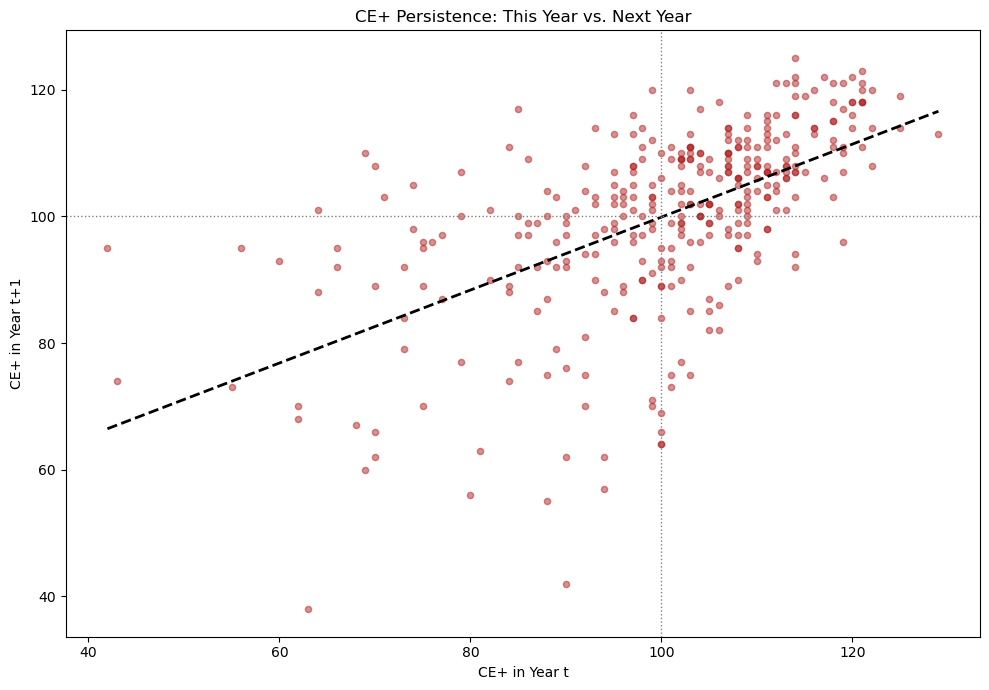

r = 0.5714, R² = 0.3265
Total observations: 351


In [27]:
#Persistence Plot: CE+ this year vs. next year
persist_df = vis_five[['Team', 'Year', 'ce_plus']].copy()
persist_df['next_year'] = persist_df['Year'] + 1

#Merge next year CE+ values for each team
persistence = persist_df.merge(
    vis_five[['Team', 'Year', 'ce_plus']],
    left_on=['Team', 'next_year'],
    right_on=['Team', 'Year'],
    suffixes=('_t', '_t1')
)
#Axes
x = persistence['ce_plus_t']
y = persistence['ce_plus_t1']

#Fit a Linear Trend Line
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

#Plot
plt.figure(figsize=(10, 7))
plt.scatter(x, y, alpha=0.5, color='firebrick', s=20)
plt.plot(x_line, y_line, color='black', linewidth=2, linestyle='--')
plt.axhline(100, color='gray', linewidth=1, linestyle=':')
plt.axvline(100, color='gray', linewidth=1, linestyle=':')
plt.xlabel('CE+ in Year t')
plt.ylabel('CE+ in Year t+1')
plt.title('CE+ Persistence: This Year vs. Next Year')
plt.tight_layout()
plt.show()

#Correlation and R²
r = x.corr(y)
print(f"r = {r:.4f}, R² = {r**2:.4f}")
print(f"Total observations: {len(persistence)}")

## 6. Pareto Frontier

The Pareto Frontier represents all team-years in which no other team both spent less money and won more games. 

Team Average payroll figures are represented by colored vertical lines.

The bottom leftmost portion of the graph is the EXTREMELY low spending teams who appear regardless of win total simply because no other team spent LESS money. The rightmost portion of the graph are the teams with extremely high payrolls that were also league leaders in wins, such that their payroll figures don't matter because no one won more than they did. These two sections don't reveal much about the tradeoff between payroll and wins and serve as the extreme cases to mark the boundaries of the frontier.

The section of the graph from ~80mil to ~150mil provides great insight. We see this section dominated by teams such as the Rays, Guardians, Brewers, Astros, and Cardinals among others. These teams are highlighted because they spent modest amounts and achieved the most league-wide success in that payroll range. The shape of the graph reveals that there is a non linear relationship between spending and success. There is a sharp increasing trend amongst win totals as payroll increases from 50 million to ~120 million. However, beyond 120 Million the relationship levels out considerably. This suggests that amongst the best most payroll efficient teams in the league there are serious diminishing returns to payrolls dollars spent above 120 million which makes sense due to the capped nature of win totals.

The average payroll lines allow us to see where some of the prominent teams lie on the Pareto Curve. In particular we see Tampa Bay despite the lowest average payroll in the league finds themselves right at the bend in the curve where the marginal return of extra payroll dollars starts significantly declining. The Brewers and Guardians find themselves in a similar payroll range, leveraging the small market budget by optimizing the marginal value of every payroll dollar. However, I believe that the Rays have the lowest average payroll not because they have the shallowest pockets every year, but because they deliberately target this section of the curve where their spending begins to rapidly lose efficacy. This is what allows them to compete with the Goliath teams on a fraction of the budget.


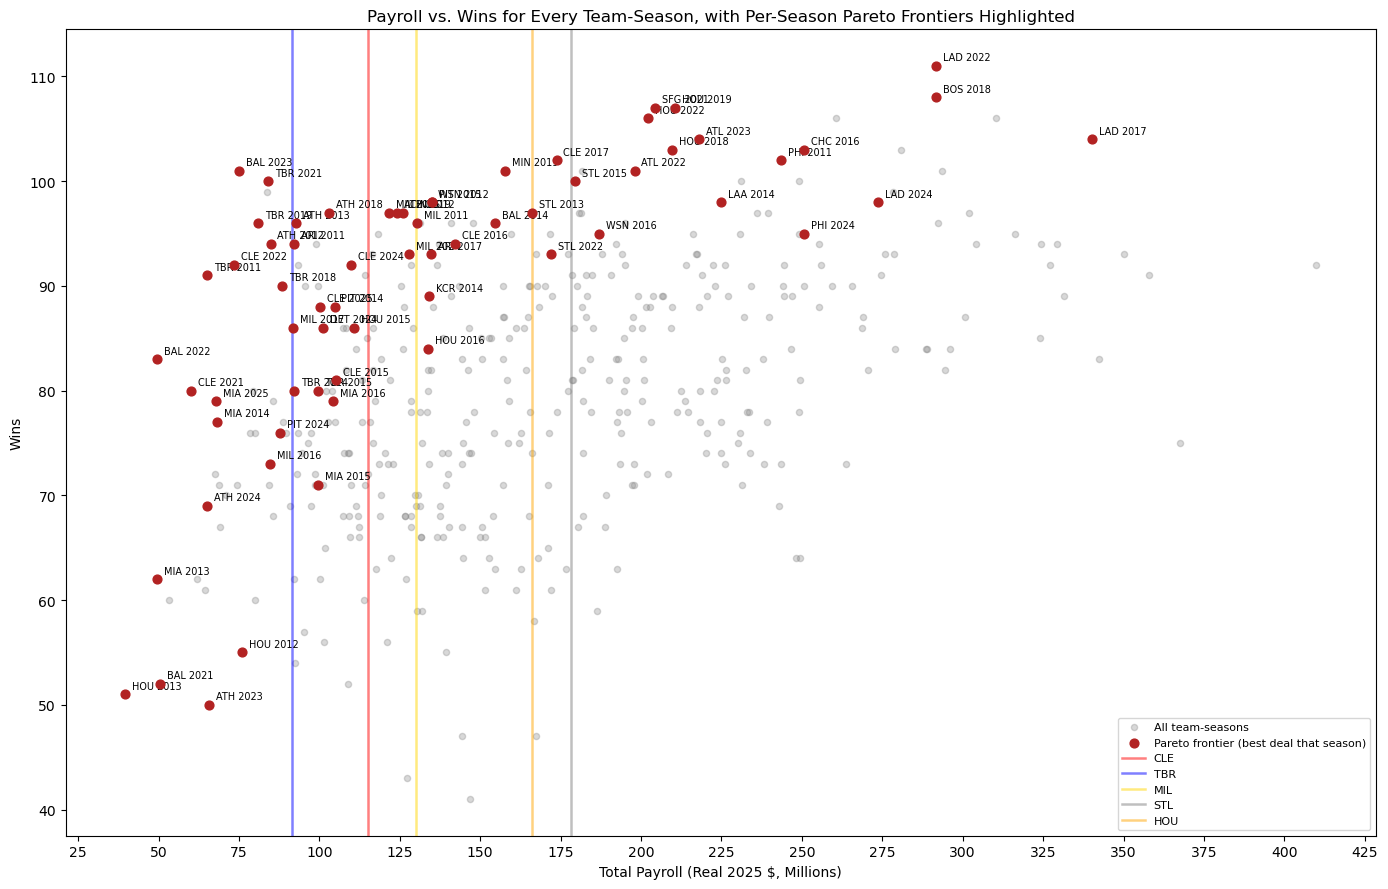

Total frontier points across all seasons: 65


In [30]:
# Pareto Frontier of Payroll vs Wins

vis_six = main_df.copy()
vis_six['payroll_millions'] = vis_six['total_payroll_real'] / 1_000_000

#Define highest wins at lowest payroll for each season (Pareto frontier)
def pareto_frontier(df, x_col='payroll_millions', y_col='W'):
    df_sorted = df.sort_values(x_col).reset_index(drop=True)
    frontier_idx = []
    max_y_so_far = -float('inf')
    for i in range(len(df_sorted)):
        if df_sorted.loc[i, y_col] > max_y_so_far:
            frontier_idx.append(df_sorted.loc[i].name)
            max_y_so_far = df_sorted.loc[i, y_col]
    return df_sorted.loc[frontier_idx]

#Plot Grey Dots
plt.figure(figsize=(14, 9))
plt.scatter(vis_six['payroll_millions'], vis_six['W'], alpha=0.3, color='gray', s=20, label='All team-seasons')

#Determine Pareto frontier for each season
all_frontier_points = []
for year in sorted(vis_six['Year'].unique()):
    year_data = vis_six[vis_six['Year'] == year]
    frontier = pareto_frontier(year_data)
    all_frontier_points.append(frontier)

#Plot Red dots
frontier_df = pd.concat(all_frontier_points)
plt.scatter(frontier_df['payroll_millions'], frontier_df['W'], color='firebrick', s=40, label='Pareto frontier (best deal that season)', zorder=5)


for _, row in frontier_df.iterrows():
    plt.annotate(f"{row['Team']} {row['Year']}", (row['payroll_millions'], row['W']),
                 textcoords="offset points", xytext=(5, 4), fontsize=7)

#Small market payroll lines
small_market_teams = ['CLE', 'TBR', 'MIL', 'STL', 'HOU']
team_colors = {'CLE': 'red', 'HOU': 'orange', 'MIL': 'gold', 'TBR': 'blue', 'STL': 'gray'}

for team in small_market_teams:
    avg = vis_six[vis_six['Team'] == team]['payroll_millions'].mean()
    plt.axvline(avg, color=team_colors[team], alpha=0.5, linewidth=1.8, label=team)

#Plot
plt.xlabel('Total Payroll (Real 2025 $, Millions)')
plt.ylabel('Wins')
plt.title('Payroll vs. Wins for Every Team-Season, with Per-Season Pareto Frontiers Highlighted')
plt.legend(loc='lower right', fontsize=8)
plt.gca().xaxis.set_major_locator(MultipleLocator(25))
plt.tight_layout()
plt.show()

print(f"Total frontier points across all seasons: {len(frontier_df)}")

In [31]:
#Frontier Appearances
frontier_counts = frontier_df['Team'].value_counts()
print(frontier_counts.head(10))

Team
HOU    7
CLE    7
TBR    6
ATH    6
MIA    5
MIL    5
BAL    4
STL    3
PIT    3
LAD    3
Name: count, dtype: int64


**Bend Range Appearances:**

We see the relationship between the efficient teams total payroll and total wins begin to level out considerably in the range of 80-120 million dollars. Beyond those payroll values the relationship is positive, but only slightly. Tampa Bay occupies this payroll zone the MOST consistently out of all teams across the years. This lends credence to the theory that they deliberately target this magnitude of roster spending to maximizing the marginal impact of their dollars.

In [ ]:
#Bend Range Appearances
in_range = main_df[(main_df['total_payroll_real'] >= 80_000_000) & (main_df['total_payroll_real'] <= 120_000_000)]
in_range_counts = in_range.groupby('Team').size().sort_values(ascending=False)
print(in_range_counts)

Team
TBR    13
MIA     8
PIT     8
ATH     8
CLE     6
KCR     5
SDP     5
ARI     5
CIN     5
WSN     4
MIL     3
CHW     3
SEA     3
BAL     3
DET     2
COL     2
MIN     2
HOU     1
TEX     1
TOR     1
dtype: int64


**Diminishing Returns:**

All team-year observations with less than 7.5 WAR were excluded as the $/WAR relationship explodes as WAR approaches 0 and these extremely poor teams do not provide significant insight (5 obs).

From this graph we see cost per WAR rises with payroll, but the relationship is weak and highly variable. A logarithmic fit explains the data only slightly better than a simple linear one. The data does not strongly support a curved, diminishing-returns shape at the team-year level. At any given payroll level, actual $/WAR varies enormously, teams spending $150-200M range from roughly $3M to $14M per win, meaning payroll size explains only a modest share of what actually drives cost efficiency. Team-specific factors like roster construction, extension timing, injury outcomes, and cost-controlled young talent versus free-agent spending appear to matter more than payroll expenditure. 

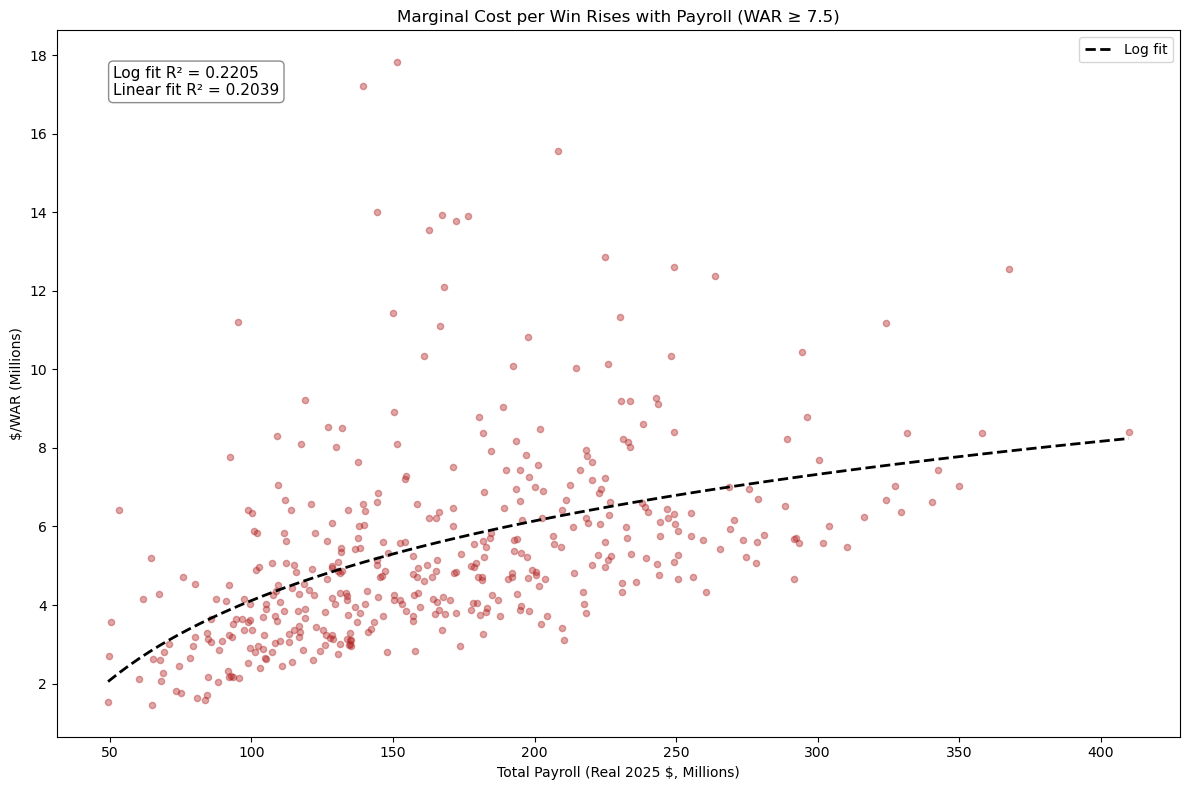

Team-years excluded (WAR < 7.5): 5


In [32]:
# Marginal Cost per Win Rises with Payroll (WAR ≥ 7.5)
vis_six_filtered = main_df[main_df['total_war'] >= 7.5].copy()
vis_six_filtered['payroll_millions'] = vis_six_filtered['total_payroll_real'] / 1_000_000

x = vis_six_filtered['payroll_millions']
y = vis_six_filtered['total_dollar_per_war'] / 1_000_000

# Log fit
log_fit = np.polyfit(np.log(x), y, 1)
log_pred = log_fit[0] * np.log(x) + log_fit[1]
log_r2 = 1 - np.sum((y - log_pred)**2) / np.sum((y - y.mean())**2)

# Linear fit
linear_fit = np.polyfit(x, y, 1)
linear_pred = linear_fit[0] * x + linear_fit[1]
linear_r2 = 1 - np.sum((y - linear_pred)**2) / np.sum((y - y.mean())**2)

# Plot
plt.figure(figsize=(12, 8))
plt.scatter(vis_six_filtered['payroll_millions'], y, alpha=0.4, color='firebrick', s=20)

#draw log fit line
x_line = np.linspace(x.min(), x.max(), 100)
y_line = log_fit[0] * np.log(x_line) + log_fit[1]
plt.plot(x_line, y_line, color='black', linewidth=2, linestyle='--', label='Log fit')

#Plot and Label
plt.xlabel('Total Payroll (Real 2025 $, Millions)')
plt.ylabel('$/WAR (Millions)')
plt.title('Marginal Cost per Win Rises with Payroll (WAR ≥ 7.5)')

plt.text(0.05, 0.95, f'Log fit R² = {log_r2:.4f}\nLinear fit R² = {linear_r2:.4f}',
          transform=plt.gca().transAxes, fontsize=11, verticalalignment='top',
          bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.9))

plt.legend()
plt.tight_layout()
plt.show()

print(f"Team-years excluded (WAR < 7.5): {len(main_df) - len(vis_six_filtered)}")

## 7. Conclusions

The goal of this project was to identify and investigate each team's unique relationship between payroll expenditure and overall success. From this, we can infer the "best" and "worst" front offices by their ability to turn each dollar into on-field value. 

Teams such as the Rays, Brewers, and Guardians are often heralded as being "magic" in their ability to compete consistently with mammoth teams despite a fraction of the spending. The analysis did reveal that these teams ARE by far the most efficient and successful small market teams, regularly showing up on the Pareto Frontier, the most winning teams at every level of expenditure. However, Tampa Bay separates themselves as the best of the best with the lowest and most consistently low average payroll in the league despite being the most successful and efficient ($/WAR) of the smaller market teams by a wide margin. I believe they are able to do this by consistently maintaining a payroll figure in the optimal Pareto range opposed to most team's payrolls fluctuating through periods of rebuilding and contention.

The analysis revealed a handful of middle market teams that have been able to maintain higher rates of efficiency than their peers even as their average payroll climbs. The Astros, Cardinals, and Braves in particular are moderate spenders who are able to leverage sustained efficiency to outperform their middle and larger market peers. 

We were also able to discern the LEAST efficient front offices in MLB to be the Angels, Giants, Rangers, and Rockies. These are teams have considerable payrolls, and while they have each had their runs of success, have not been consistently able to perform up to their payroll. 

CE+ was developed as an easily interpretable metric that evaluates how efficient a front office is at turning payroll into WAR relative to league average. The metric allows us to evaluate individual season performance rather than holistic organizational efficiency. Unsurprisingly, the Rays are way out in front in this metric, with the Guardians and Brewers also looked upon favorably, further validating these front offices as elite performers relative to their competition.

Dead Money % was also developed to gauge how effectively each team keeps their payroll on the field. Dead Money % was found to have a definitive association with Wins, however this is expected because WAR does as well and WAR can only be accrued when players are on the field. The Astros, Brewers, and Cardinals once again appear very strong by this metric, contextualizing how they might be finding their way to success despite their middling payrolls. Most interestingly, the most efficient front office, the Tampa Bay Rays, are quite POOR in terms of this metric. This COULD be due to a high rate of injuries relative to payroll size but a unique ability to maximize player WAR when they ARE on the active 26-man roster. 